In [1]:
import torch
from torchvision import datasets
import matplotlib.pyplot as plt

# Download MNIST (only the raw data, no automatic processing)
train_full = datasets.MNIST(root="data", train=True, download=True)
test_raw   = datasets.MNIST(root="data", train=False, download=True)

# Take out the images and labels as plain tensors
X_train_full = train_full.data      # the images
y_train_full = train_full.targets   # the correct answers (0-9)
X_test = test_raw.data
y_test = test_raw.targets

print("Train images:", X_train_full.shape)
print("Test images:", X_test.shape)
print("Pixel type:", X_train_full.dtype)
print("Min pixel:", X_train_full.min().item(), " Max pixel:", X_train_full.max().item())

100%|██████████| 9.91M/9.91M [00:00<00:00, 59.8MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.75MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 14.4MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.24MB/s]

Train images: torch.Size([60000, 28, 28])
Test images: torch.Size([10000, 28, 28])
Pixel type: torch.uint8
Min pixel: 0  Max pixel: 255


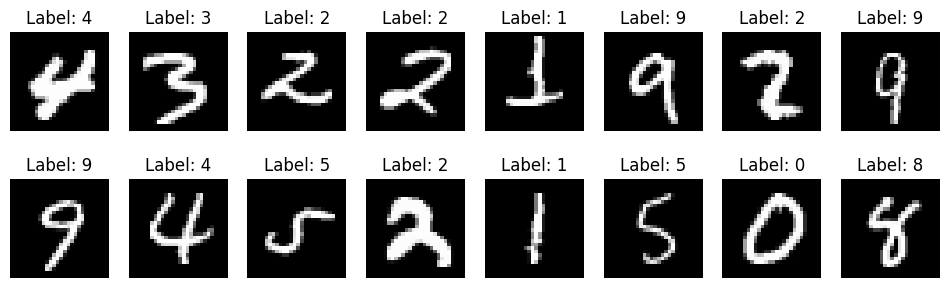

In [14]:
idx = torch.randint(0, 60000, (16,))   # 16 random positions
fig, axes = plt.subplots(2, 8, figsize=(12, 3.5))
for ax, i in zip(axes.flat, idx):
    ax.imshow(X_train_full[i], cmap="gray")
    ax.set_title(f"Label: {y_train_full[i].item()}")
    ax.axis("off")
plt.show()

In [15]:
print(torch.bincount(y_train_full))

tensor([5923, 6742, 5958, 6131, 5842, 5421, 5918, 6265, 5851, 5949])


In [16]:
X_train_full = X_train_full.float() / 255.0
X_test = X_test.float() / 255.0

X_train_full = X_train_full.unsqueeze(1)
X_test = X_test.unsqueeze(1)

print("New shape:", X_train_full.shape)
print("Min:", X_train_full.min().item(), " Max:", X_train_full.max().item())

New shape: torch.Size([60000, 1, 28, 28])
Min: 0.0  Max: 1.0


In [20]:
print("New shape:", X_train_full.shape)
print("Min:", X_train_full.min().item(), " Max:", X_train_full.max().item())

New shape: torch.Size([60000, 1, 28, 28])
Min: 0.0  Max: 1.0


In [27]:
torch.manual_seed(42)

perm = torch.randperm(60000)
val_idx   = perm[:10000]
train_idx = perm[10000:]

X_train, y_train = X_train_full[train_idx], y_train_full[train_idx]
X_val,   y_val   = X_train_full[val_idx],   y_train_full[val_idx]

print("Train:", X_train.shape[0])
print("Validation:", X_val.shape[0])
print("Test:", X_test.shape[0])

Train: 50000
Validation: 10000
Test: 10000


In [28]:
from torch.utils.data import TensorDataset, DataLoader

train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=64, shuffle=True)
val_loader   = DataLoader(TensorDataset(X_val, y_val),     batch_size=256)
test_loader  = DataLoader(TensorDataset(X_test, y_test),   batch_size=256)

images, labels = next(iter(train_loader))
print("One batch:", images.shape, labels.shape)

One batch: torch.Size([64, 1, 28, 28]) torch.Size([64])


In [29]:
import torch.nn as nn

torch.manual_seed(42)

cnn = nn.Sequential(
    # Block 1
    nn.Conv2d(in_channels=1, out_channels=32, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),

    # Block 2
    nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),

    # Classifier (dense head)
    nn.Flatten(),
    nn.Linear(64 * 7 * 7, 128),
    nn.ReLU(),
    nn.Linear(128, 10),
)

print(cnn)

Sequential(
  (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (4): ReLU()
  (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Flatten(start_dim=1, end_dim=-1)
  (7): Linear(in_features=3136, out_features=128, bias=True)
  (8): ReLU()
  (9): Linear(in_features=128, out_features=10, bias=True)
)


In [30]:
images, labels = next(iter(train_loader))
scores = cnn(images)
print("Output shape:", scores.shape)
print("Scores for the first photo:", scores[0])

predictions = scores.argmax(dim=1)
print("Predicted:", predictions[:10].tolist())
print("Correct:  ", labels[:10].tolist())

correct = 0
with torch.no_grad():
    for images, labels in val_loader:
        predictions = cnn(images).argmax(dim=1)
        correct += (predictions == labels).sum().item()
print(f"Validation accuracy (untrained): {correct / len(X_val):.2%}")

# 4. Count the parameters
total = sum(p.numel() for p in cnn.parameters())
print(f"Parameters: {total:,}")

Output shape: torch.Size([64, 10])
Scores for the first photo: tensor([ 0.0399,  0.0015,  0.0066,  0.0090,  0.0575, -0.0055, -0.0380, -0.0053,
         0.0357, -0.1116], grad_fn=<SelectBackward0>)
Predicted: [4, 4, 3, 4, 4, 0, 4, 4, 4, 4]
Correct:   [5, 2, 5, 4, 0, 2, 8, 6, 5, 3]
Validation accuracy (untrained): 14.92%
Parameters: 421,642


In [31]:
loss_fn = nn.CrossEntropyLoss()
EPOCHS = 10

def evaluate(model, loader):
    model.eval()
    total_loss, correct, count = 0, 0, 0
    with torch.no_grad():
        for images, labels in loader:
            scores = model(images)
            total_loss += loss_fn(scores, labels).item() * len(labels)
            correct += (scores.argmax(dim=1) == labels).sum().item()
            count += len(labels)
    return total_loss / count, correct / count


def train_model(model, epochs=EPOCHS, lr=0.001):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

    for epoch in range(epochs):
        model.train()
        total_loss, correct, count = 0, 0, 0

        for images, labels in train_loader:
            scores = model(images)              # 1. guess
            loss = loss_fn(scores, labels)      # 2. how wrong?

            optimizer.zero_grad()               # clear old blame
            loss.backward()                     # 3. who's to blame?
            optimizer.step()                    # 4. adjust the knobs

            total_loss += loss.item() * len(labels)
            correct += (scores.argmax(dim=1) == labels).sum().item()
            count += len(labels)

        train_loss, train_acc = total_loss / count, correct / count
        val_loss, val_acc = evaluate(model, val_loader)

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        print(f"Epoch {epoch+1}/{epochs} | "
              f"train loss {train_loss:.4f}, acc {train_acc:.2%} | "
              f"val loss {val_loss:.4f}, acc {val_acc:.2%}")

    return history


torch.manual_seed(42)
cnn_history = train_model(cnn)

Epoch 1/10 | train loss 0.2095, acc 93.54% | val loss 0.0730, acc 97.85%
Epoch 2/10 | train loss 0.0546, acc 98.30% | val loss 0.0522, acc 98.35%
Epoch 3/10 | train loss 0.0369, acc 98.86% | val loss 0.0552, acc 98.43%
Epoch 4/10 | train loss 0.0265, acc 99.11% | val loss 0.0386, acc 98.82%
Epoch 5/10 | train loss 0.0215, acc 99.28% | val loss 0.0472, acc 98.57%
Epoch 6/10 | train loss 0.0155, acc 99.52% | val loss 0.0417, acc 98.81%
Epoch 7/10 | train loss 0.0126, acc 99.59% | val loss 0.0496, acc 98.81%
Epoch 8/10 | train loss 0.0114, acc 99.65% | val loss 0.0617, acc 98.54%
Epoch 9/10 | train loss 0.0094, acc 99.70% | val loss 0.0402, acc 99.03%
Epoch 10/10 | train loss 0.0071, acc 99.76% | val loss 0.0449, acc 98.92%


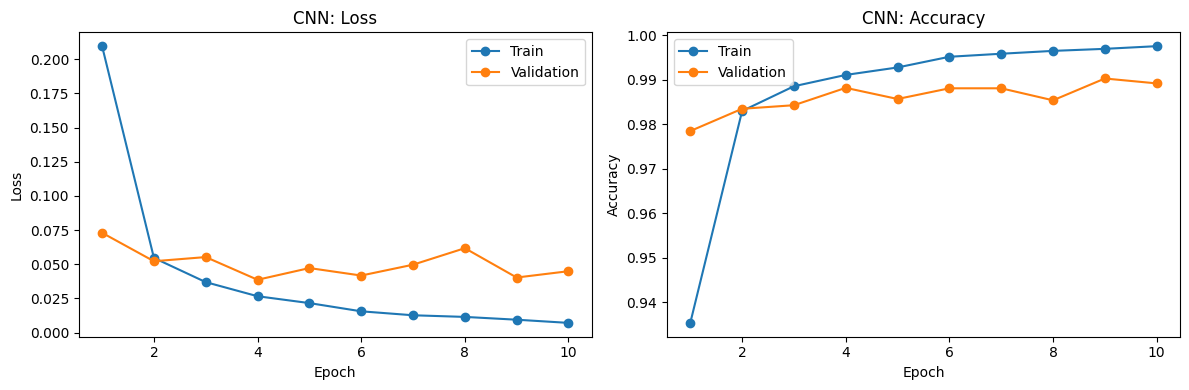

In [32]:
import os
os.makedirs("images", exist_ok=True)

def plot_history(history, title, filename):
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

    ax1.plot(epochs, history["train_loss"], "o-", label="Train")
    ax1.plot(epochs, history["val_loss"], "o-", label="Validation")
    ax1.set_title(f"{title}: Loss")
    ax1.set_xlabel("Epoch")
    ax1.set_ylabel("Loss")
    ax1.legend()

    ax2.plot(epochs, history["train_acc"], "o-", label="Train")
    ax2.plot(epochs, history["val_acc"], "o-", label="Validation")
    ax2.set_title(f"{title}: Accuracy")
    ax2.set_xlabel("Epoch")
    ax2.set_ylabel("Accuracy")
    ax2.legend()

    plt.tight_layout()
    plt.savefig(f"images/{filename}", dpi=120)
    plt.show()

plot_history(cnn_history, "CNN", "cnn_curves.png")

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=256, bias=True)
  (2): ReLU()
  (3): Linear(in_features=256, out_features=128, bias=True)
  (4): ReLU()
  (5): Linear(in_features=128, out_features=10, bias=True)
)
Parameters: 235,146
Epoch 1/10 | train loss 0.3085, acc 90.98% | val loss 0.1659, acc 95.05%
Epoch 2/10 | train loss 0.1188, acc 96.37% | val loss 0.1271, acc 96.11%
Epoch 3/10 | train loss 0.0789, acc 97.63% | val loss 0.0988, acc 96.97%
Epoch 4/10 | train loss 0.0572, acc 98.22% | val loss 0.0822, acc 97.59%
Epoch 5/10 | train loss 0.0402, acc 98.78% | val loss 0.0922, acc 97.17%
Epoch 6/10 | train loss 0.0335, acc 98.95% | val loss 0.1004, acc 97.05%
Epoch 7/10 | train loss 0.0270, acc 99.14% | val loss 0.0962, acc 97.40%
Epoch 8/10 | train loss 0.0203, acc 99.35% | val loss 0.0956, acc 97.47%
Epoch 9/10 | train loss 0.0165, acc 99.45% | val loss 0.0860, acc 97.84%
Epoch 10/10 | train loss 0.0162, acc 99.43% | val loss 0.1148,

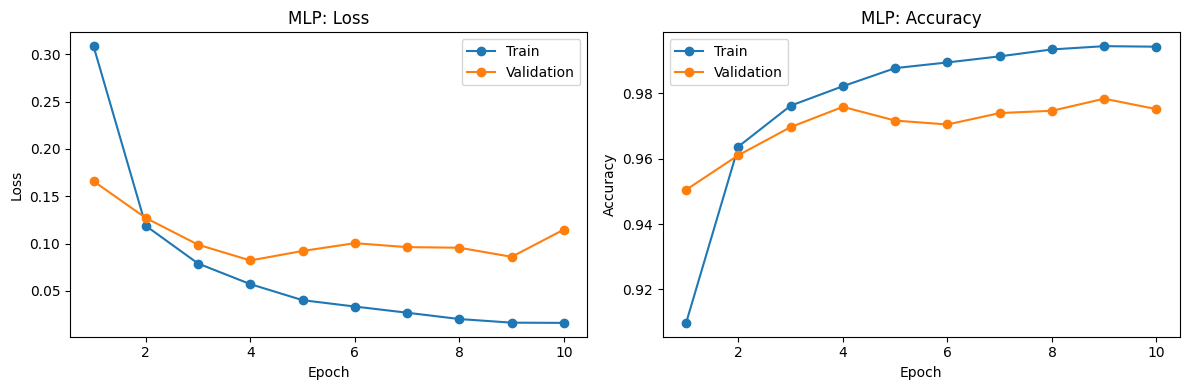

In [33]:
torch.manual_seed(42)

mlp = nn.Sequential(
    nn.Flatten(),
    nn.Linear(28 * 28, 256),
    nn.ReLU(),
    nn.Linear(256, 128),
    nn.ReLU(),
    nn.Linear(128, 10),
)

print(mlp)
print(f"Parameters: {sum(p.numel() for p in mlp.parameters()):,}")

torch.manual_seed(42)
mlp_history = train_model(mlp)

plot_history(mlp_history, "MLP", "mlp_curves.png")

Model  |   Params | Test loss | Test acc | Errors
CNN    |  421,642 |    0.0384 |   98.94% |    106
MLP    |  235,146 |    0.1087 |   97.38% |    262


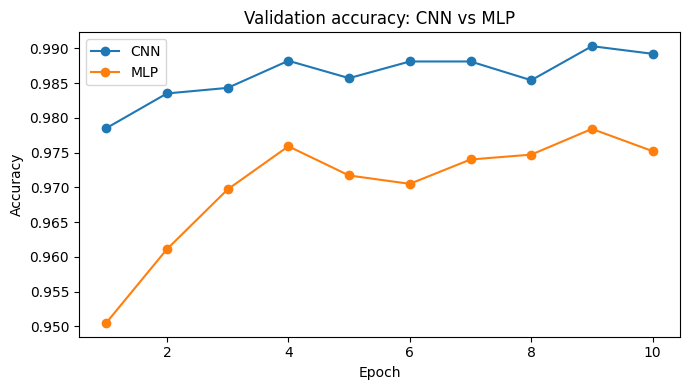

In [34]:
cnn_test_loss, cnn_test_acc = evaluate(cnn, test_loader)
mlp_test_loss, mlp_test_acc = evaluate(mlp, test_loader)

print(f"{'Model':<6} | {'Params':>8} | {'Test loss':>9} | {'Test acc':>8} | {'Errors':>6}")
print(f"{'CNN':<6} | {421642:>8,} | {cnn_test_loss:>9.4f} | {cnn_test_acc:>8.2%} | {round((1-cnn_test_acc)*10000):>6}")
print(f"{'MLP':<6} | {235146:>8,} | {mlp_test_loss:>9.4f} | {mlp_test_acc:>8.2%} | {round((1-mlp_test_acc)*10000):>6}")

# Validation accuracy of both models on one chart
epochs = range(1, EPOCHS + 1)
plt.figure(figsize=(7, 4))
plt.plot(epochs, cnn_history["val_acc"], "o-", label="CNN")
plt.plot(epochs, mlp_history["val_acc"], "o-", label="MLP")
plt.title("Validation accuracy: CNN vs MLP")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.tight_layout()
plt.savefig("images/cnn_vs_mlp.png", dpi=120)
plt.show()

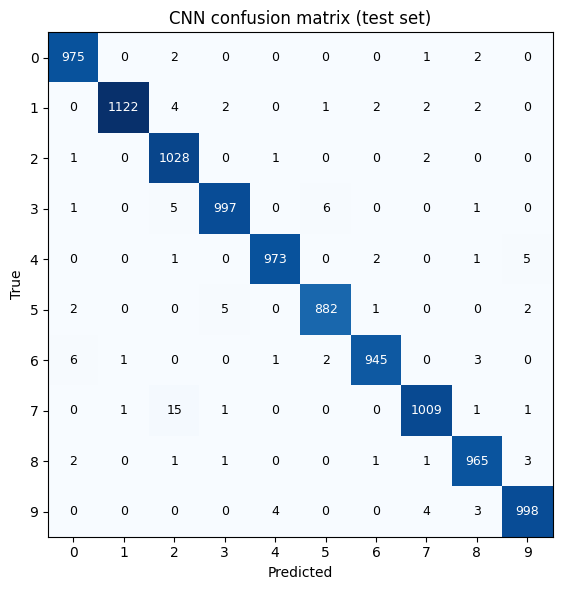

True 7 -> predicted 2: 15 times
True 3 -> predicted 5: 6 times
True 6 -> predicted 0: 6 times
True 4 -> predicted 9: 5 times
True 3 -> predicted 2: 5 times


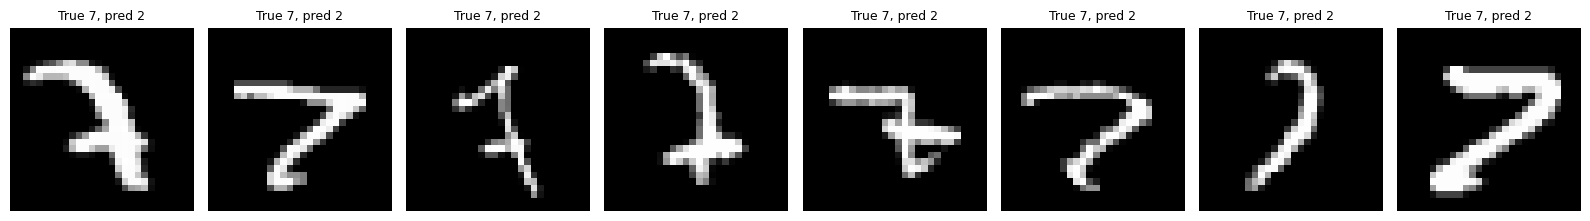

In [35]:
# 1. Get the CNN's prediction for every test image
cnn.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for images, labels in test_loader:
        all_preds.append(cnn(images).argmax(dim=1))
        all_labels.append(labels)
all_preds = torch.cat(all_preds)
all_labels = torch.cat(all_labels)

# 2. Build the 10x10 confusion matrix
cm = torch.zeros(10, 10, dtype=torch.int64)
for true, pred in zip(all_labels, all_preds):
    cm[true, pred] += 1

# 3. Draw it
fig, ax = plt.subplots(figsize=(7, 6))
ax.imshow(cm, cmap="Blues")
for i in range(10):
    for j in range(10):
        value = cm[i, j].item()
        color = "white" if value > cm.max() / 2 else "black"
        ax.text(j, i, value, ha="center", va="center", color=color, fontsize=9)
ax.set_xticks(range(10))
ax.set_yticks(range(10))
ax.set_xlabel("Predicted")
ax.set_ylabel("True")
ax.set_title("CNN confusion matrix (test set)")
plt.tight_layout()
plt.savefig("images/confusion_matrix.png", dpi=120)
plt.show()

# 4. Top 5 most confused pairs
mistakes = cm.clone()
mistakes.fill_diagonal_(0)
values, positions = mistakes.flatten().topk(5)
for v, pos in zip(values, positions):
    print(f"True {pos.item() // 10} -> predicted {pos.item() % 10}: {v.item()} times")

# 5. Look at the mistakes for the #1 pair
t, p = positions[0].item() // 10, positions[0].item() % 10
wrong = ((all_labels == t) & (all_preds == p)).nonzero().flatten()[:8]
fig, axes = plt.subplots(1, len(wrong), figsize=(2 * len(wrong), 2.4), squeeze=False)
for ax, i in zip(axes[0], wrong):
    ax.imshow(X_test[i, 0], cmap="gray")
    ax.set_title(f"True {t}, pred {p}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.savefig("images/top_confusion_examples.png", dpi=120)
plt.show()

In [36]:
os.makedirs("models", exist_ok=True)
torch.save(cnn.state_dict(), "models/cnn_mnist.pt")
print("Saved. File size:", round(os.path.getsize("models/cnn_mnist.pt") / 1024), "KB")

Saved. File size: 1651 KB


In [37]:
def build_cnn():
    return nn.Sequential(
        nn.Conv2d(1, 32, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Conv2d(32, 64, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Flatten(),
        nn.Linear(64 * 7 * 7, 128),
        nn.ReLU(),
        nn.Linear(128, 10),
    )

loaded_cnn = build_cnn()
_, acc_empty = evaluate(loaded_cnn, test_loader)
print(f"New empty model:        {acc_empty:.2%}")

loaded_cnn.load_state_dict(torch.load("models/cnn_mnist.pt"))
_, acc_loaded = evaluate(loaded_cnn, test_loader)
print(f"After loading weights:  {acc_loaded:.2%}")
print(f"Original trained model: {cnn_test_acc:.2%}")

New empty model:        9.26%
After loading weights:  98.94%
Original trained model: 98.94%


In [40]:
import numpy as np
import glob
from PIL import Image, ImageOps, ImageFilter
from scipy import ndimage

def preprocess(path):
    steps = {}

    # 1. Open the photo (and fix phone rotation)
    img = ImageOps.exif_transpose(Image.open(path))
    steps["1. original"] = np.array(img.convert("RGB"))

    # 2. Grayscale: 3 color channels -> 1
    gray = img.convert("L")
    steps["2. grayscale"] = np.array(gray)

    # 3. Invert relative to the local background (removes shadows)
    radius = max(gray.size) // 20
    background = np.array(gray.filter(ImageFilter.GaussianBlur(radius))).astype(np.float32)
    ink = np.clip(background - np.array(gray).astype(np.float32), 0, None)
    steps["3. inverted (shadow removed)"] = ink

    # 4. Clean: keep strong strokes only, then keep only the big connected blobs (the digit)
    mask = ink > ink.max() * 0.4
    labels, n = ndimage.label(mask)
    if n > 1:
        sizes = ndimage.sum(mask, labels, range(1, n + 1))
        keep = [i + 1 for i, s in enumerate(sizes) if s >= sizes.max() * 0.2]
        mask = np.isin(labels, keep)
    cleaned = np.where(mask, ink, 0)
    cleaned = cleaned / cleaned.max() * 255

    # 5. Crop to the digit
    ys, xs = np.nonzero(cleaned)
    cropped = cleaned[ys.min():ys.max() + 1, xs.min():xs.max() + 1]
    steps["4. cleaned + cropped"] = cropped

    # 6. Resize to fit 20x20 (keep shape), then center on a 28x28 black canvas
    h, w = cropped.shape
    scale = 20 / max(h, w)
    new_w, new_h = max(1, round(w * scale)), max(1, round(h * scale))
    small = Image.fromarray(cropped.astype(np.uint8)).resize((new_w, new_h), Image.LANCZOS)
    canvas = Image.new("L", (28, 28), 0)
    canvas.paste(small, ((28 - new_w) // 2, (28 - new_h) // 2))
    final = np.array(canvas)
    steps["5. final 28x28"] = final

    # 7. Normalize to 0-1 and shape [1, 1, 28, 28], exactly like the training data
    x = torch.tensor(final, dtype=torch.float32) / 255.0
    x = x.unsqueeze(0).unsqueeze(0)
    return steps, x

Found: ['my_digits/1.jpeg', 'my_digits/3.jpeg', 'my_digits/4.jpeg', 'my_digits/5.jpeg', 'my_digits/thin_8.jpeg']


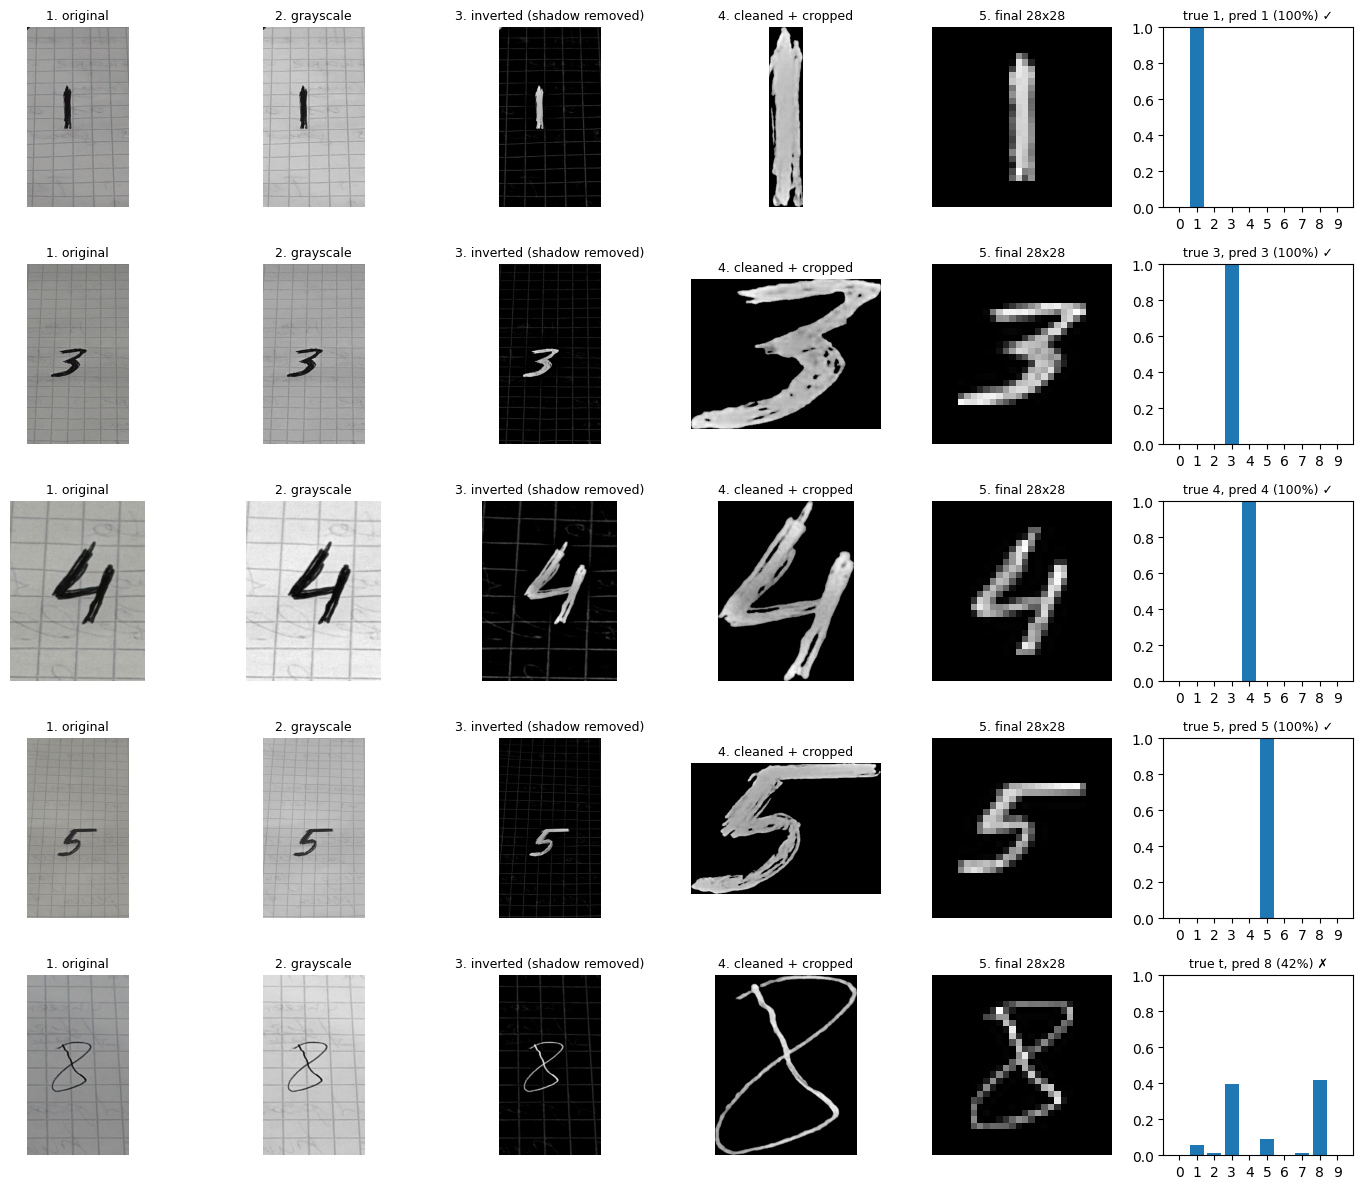

In [47]:
paths = sorted(glob.glob("my_digits/*"))
print("Found:", paths)

loaded_cnn.eval()
fig, axes = plt.subplots(len(paths), 6, figsize=(14, 2.4 * len(paths)), squeeze=False)

for row, path in zip(axes, paths):
    steps, x = preprocess(path)
    with torch.no_grad():
        probs = torch.softmax(loaded_cnn(x), dim=1)[0]
    pred = probs.argmax().item()
    true = os.path.basename(path)[0]

    for ax, (name, image) in zip(row, steps.items()):
        ax.imshow(image, cmap="gray")
        ax.set_title(name, fontsize=9)
        ax.axis("off")

    row[5].bar(range(10), probs.numpy())
    row[5].set_xticks(range(10))
    row[5].set_ylim(0, 1)
    mark = "✓" if str(pred) == true else "✗"
    row[5].set_title(f"true {true}, pred {pred} ({probs[pred]:.0%}) {mark}", fontsize=9)

plt.tight_layout()
plt.savefig("images/custom_digits.png", dpi=120)
plt.show()